# Particle trajectories and capture zones with `martpy.Trajectory`

Everything a MARTHE trajectory run produces, read through the project: the
seeding file (`.deptr`) the `.rma` points at, the grid (`permh`) to locate
cell records and size the masks, and `trajmar.out` written next to the `.rma`.

    read_trajectory  ->  Trajectory
        .to_shape        the paths, as points or lines, for QGIS
        .build_capture   the capture zone of every seeding point -> CaptureZone
        .build_mask      a boolean raster of it                   -> CaptureMask
        .summary         one row per seeding point
        .plot            all of the above on one map

The model used here is `cap_z/MRN_M400_L3_G200_v12a_steady_CZ` (35 seeding
points, 100 particles each, three layers, a 200 m gigogne in a 400 m grid).
Change `RMA` and `OUT` to run it on another one.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import martpy as mart

RMA = r'C:\Users\Ranveer\Desktop\cap_z\MRN_M400_L3_G200_v12a_steady_CZ\mrn_v11.rma'
OUT = r'C:\Users\Ranveer\Desktop\cap_z\notebook_out'
os.makedirs(OUT, exist_ok=True)
pd.set_option('display.width', 160)

## 1. Read the run

`read_trajectory` (a shortcut for `Trajectory.from_project`) takes the `.rma`
path or a `MartProject`.  `trajmar.out` is looked for next to the `.rma`;
pass `trajmar=` to point elsewhere (a `.gz` is fine).  `crs` defaults to
Lambert-93.

In [3]:
tr = mart.read_trajectory(RMA)
print(tr)

Trajectory: 3500 paths, 498887 vertices, 35 seeding points (0 unattributed)
    W01: 100 paths
    W02: 100 paths
    W03: 100 paths
    W04: 100 paths
    W05: 100 paths
    W06: 100 paths
    W07: 100 paths
    W08: 100 paths
    W09: 100 paths
    W10: 100 paths
    W11: 100 paths
    W12: 100 paths
    W13: 100 paths
    W14: 100 paths
    W15: 100 paths
    W16: 100 paths
    W17: 100 paths
    W18: 100 paths
    W19: 100 paths
    W20: 100 paths
    W21: 100 paths
    W22: 100 paths
    W23: 100 paths
    W24: 100 paths
    W25: 100 paths
    W26: 100 paths
    W27: 100 paths
    W28: 100 paths
    W29: 100 paths
    W30: 100 paths
    W31: 100 paths
    W32: 100 paths
    W33: 100 paths
    W34: 100 paths
    W35: 100 paths



What was read: the seeding points (with x, y filled from the grid for
cell records), and the vertices with their altitude `z`, travel time `t` and
`layer` -- the fifth column of `trajmar.out`, so no elevation lookup is
needed to know which layer a particle is in.

In [4]:
display(tr.seeds.head())

print(' vertices', len(tr.xy), 
      '\n z', tr.z.min().round(1), '..', tr.z.max().round(1),
      '\n layers', np.unique(tr.layer), 
      '\n native cell (smallest)', tr._native_cellsize(), 'm')

,form,col,row,layer,inest,x,y,z,npart,radius,group
key,,,,,,,,,,,
W01,xy,-1,-1,-1,-1,567056.0,6933156.0,64.95,100,142.0,111
W02,xy,-1,-1,-1,-1,565802.0,6928087.0,14.66,100,142.0,115
W03,xy,-1,-1,-1,-1,566461.0,6929507.0,16.98,100,142.0,114
W04,xy,-1,-1,-1,-1,570825.0,6925540.0,36.26,100,142.0,119
W05,xy,-1,-1,-1,-1,570477.0,6925579.0,36.34,100,142.0,120


 vertices 498887 
 z -108.0 .. 175.3 
 layers [1 2 3] 
 native cell (smallest) 200.0 m


### Which seeding point does a trajectory belong to?

MARTHE writes the `Group =` tag of a location trajectory (with sometime a single digit wrapped if run from WinMARTHE --a bug--).   `method='auto'`
(the default) trusts the tag only when every trajectory carries one, the `G=`
of the seeding file are unique and every tag is among them; otherwise it
falls back to the geometric test -- the N particles are released on the
circle of radius R about the seeding point, so |d - R| ~ 0 identifies it.

therefore sometime this build writes the full tag, and the two methods sometime disagree if two seeding points sit closer together than 2R if particles lie on the intersection of their rings. To avoid this it is better to define the *.deptr file in notebook and run it without WinMARTHE (if facing this issue).

In [5]:
ring = mart.read_trajectory(RMA, method='ring')
print('auto resolved to:', tr.method)

# check wheather the two method disagrees
d = np.flatnonzero(ring.owner != tr.owner)
print(len(d), 'trajectories differ:', [(tr.keys[tr.owner[j]], ring.keys[ring.owner[j]]) for j in d])

auto resolved to: group
2 trajectories differ: [('W04', 'W06'), ('W06', 'W04')]


## 2. The paths as a shapefile / geopackage

Every feature carries `key` (W01 ...), `group` (the real `G=` tag) and `traj`.

* `kind='point'` -- one feature per vertex with the values exactly as
  `trajmar.out` writes them: `x, y, z, t, layer`.
* `kind='line'` -- one feature per pair of consecutive vertices, so a path can
  be classified along its length in QGIS: `from`, `to`, and `z`, `t` as the
  mean of the two ends, `layer` as the deeper of the two.

`id` selects seeding points: `-1` for all (default), a key (`'W03'`), the
`G=` group of the seeding record (`111`), a 1-based number in file order, or
a list of any of these -- a number is taken as a `G=` group when one seeding
point carries it, else as the file-order number.  The extension picks the
driver.

In [9]:
pts = tr.to_shape(os.path.join(OUT, 'paths_points_W01.shp'), kind='point', id="W01")
display(pts.head(3))

lines = tr.to_shape(os.path.join(OUT, 'paths_lines.gpkg'), kind='line', id=[117, 'W03'])
display(lines.head(3))

,key,group,traj,vertex,x,y,z,t,layer,geometry
0,W01,111,1,0,567056.0,6933298.0,64.95000,0.000000,3,POINT (567056 6933298)
1,W01,111,1,1,567056.3,6933307.0,64.76454,0.004098,3,POINT (567056.3 6933307)
2,W01,111,1,2,567056.7,6933316.0,64.57948,0.008195,3,POINT (567056.7 6933316)


,key,group,traj,seg,from,to,z,t,layer,geometry
0,W07,117,601,0,"(567254.00, 6927469.00)","(567277.10, 6927446.00)",15.6,0.007536,3,"LINESTRING (567254 6927469, 567277.1 6927446)"
1,W07,117,601,1,"(567277.10, 6927446.00)","(567299.30, 6927422.00)",15.6,0.022608,3,"LINESTRING (567277.1 6927446, 567299.3 6927422)"
2,W07,117,601,2,"(567299.30, 6927422.00)","(567320.60, 6927396.00)",15.6,0.037679,3,"LINESTRING (567299.3 6927422, 567320.6 6927396)"


## 3. Capture zones

Three ways from a bundle of backward pathlines to a polygon, chosen by
`method`:

* **envelope** (default) -- the union of the trajectories between angularly
  adjacent pathlines (Tosco et al. 2008).  Every path is an edge of two trajectories,
  so none can be left outside.  A trajectory whose two paths end far apart
  (`gap_factor` x the median gap, or `max_gap` metres) has split around a
  stagnation point and is not filled.
* **hull** -- a concave hull of the vertices; `ratio` 0 clings to every notch,
  1 is the convex hull.  Cheap, but it cannot tell which points belong to
  which path and can cut across one.
* **track** -- the raster cells the paths pass through, closed
  (`close_cells`) and contoured after a blur (`sigma`), on `cellsize`
  (default: the native gigogne cell).

`offset_m` is the standoff from the outermost path in every method, and the
only argument that moves the boundary outward.

In [10]:
cz = tr.build_capture(method='envelope', offset_m=20.0)
print(cz)

display(cz.gdf.head())
cz.to_shape(os.path.join(OUT, 'capture_envelope.shp'))

CaptureZone(envelope): 35 zones, 212.011 km2


,key,group,x,y,ntraj,area_km2,method,geometry
0,W01,111,567056.0,6933156.0,100,13.3945,envelope,"POLYGON ((564723.014 6937542.475, 564723.016 6..."
1,W02,115,565802.0,6928087.0,100,12.1438,envelope,"POLYGON ((565620.442 6928092.808, 565620.432 6..."
2,W03,114,566461.0,6929507.0,100,12.8245,envelope,"POLYGON ((566279.443 6929512.834, 566279.34 69..."
3,W04,119,570825.0,6925540.0,100,6.2712,envelope,"POLYGON ((570643.447 6925534.198, 570643.32 69..."
4,W05,120,570477.0,6925579.0,100,7.6041,envelope,"POLYGON ((570295.445 6925584.79, 570295.426 69..."


'C:\\Users\\Ranveer\\Desktop\\cap_z\\notebook_out\\capture_envelope.shp'

In [12]:
# the three methods on the same seeding point
areas = {}
for m, kw in [('envelope', {}), ('hull', {}), ('hull', {'ratio': 1.0}),
              ('track', {}), ('track', {'cellsize': 100.})]:
    z = tr.build_capture(method=m, id='W01', **kw)
    areas[f"{m} {kw}"] = float(z.gdf.area_km2.iloc[0])
pd.Series(areas, name='W01 km2').round(2)

envelope {}                  13.39
hull {}                      13.92
hull {'ratio': 1.0}          28.02
track {}                     14.92
track {'cellsize': 100.0}    14.10
Name: W01 km2, dtype: float64

The ablation in one line each: `offset_m` scales every zone;
`gap_factor` matters only where the first and last particle of a ring would
otherwise be joined across uncaptured ground; the hull is the envelope's
match at `ratio=0.10` and twice it at `ratio=1`; track over-estimates by the
cell size.

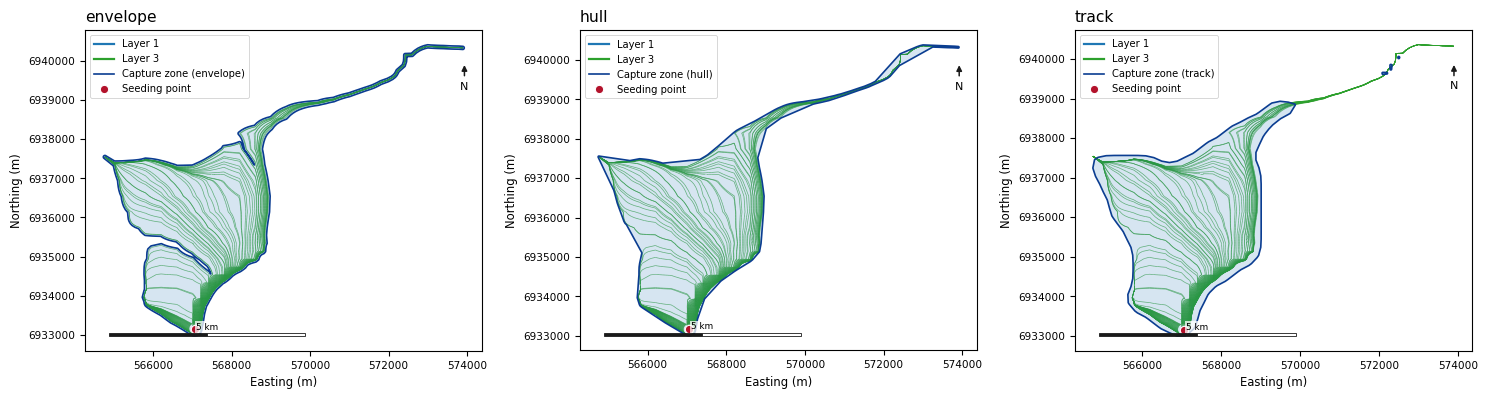

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, m in zip(axs, ('envelope', 'hull', 'track')):
    tr.build_capture(method=m, id='W01')
    tr.plot(ax=ax, capture=True, id='W01', basemap=False, title=m,
            legend_loc='upper left', base_fontsize=8)
plt.tight_layout()

## 4. Capture masks

This module has been added to generate capture probability of a model grid cell, for stochastic studies. The `build_mask` can be called and the mask can be saved `save_mask` in a loop for each set of model realisation for further grid based probability determination.

The `build_mask` puts every seeding point's zone on one boolean raster,
`(nzone, nrow, ncol)`, north-up.  `cellsize` defaults to the smallest cell
of the model grid -- the gigogne mesh.  `close_cells` bridges the gaps between
neighbouring paths; `offset_cells` is the only step that enlarges the zone.
Both are counted in cells, so their effect scales with `cellsize`: a 3-cell
closing is 600 m at the native 200 m here, which is why the mask runs
1.1-2.7x the envelope on this model.

In [9]:
cm = tr.build_mask()                      # native 200 m
print(cm)
cm100 = tr.build_mask(cellsize=100., close_cells=2)
print(cm100)

CaptureMask: 35 zones on 356 x 410 cells of 200 m, 178.360 km2 captured


CaptureMask: 35 zones on 708 x 816 cells of 100 m, 156.640 km2 captured


In [10]:
# to disk and back: .npz is exact and carries the geometry, .tif has one band per seed
p = cm100.save_mask(os.path.join(OUT, 'mask_100m.npz'))
cm100.save_mask(os.path.join(OUT, 'mask_100m.tif'))
from martpy.utils.trajectory import CaptureMask
back = CaptureMask.load_mask(p)
print('identical after reload:', (back.array == cm100.array).all(), '| keys', back.keys[:3], '| crs', back.crs)

identical after reload: True | keys ['W01', 'W02', 'W03'] | crs EPSG:2154


## 5. Summary table

One row per seeding point: the seed as declared (`group` is its `G=` tag),
how many paths it got and
by which attribution, mean path length, longest travel time, then the area
of whatever has been built so far (NaN for a seed a product does not
cover).

In [17]:
tr.build_capture(method='envelope', offset_m=20.)
tr.build_mask(cellsize=100., close_cells=2)
summ = tr.summary()
summ.to_csv(os.path.join(OUT, 'summary.csv'))
summ.head(10)

,group,x,y,z,layer,radius,npart,ntraj,method,path_m,t_max,capture_method,capture_km2,mask_cell_m,mask_km2
key,,,,,,,,,,,,,,,
W01,111,567056.0,6933156.0,64.95,3,142.0,100,100,group,5305.394373,2584.085,envelope,13.3945,100.0,14.13
W02,115,565802.0,6928087.0,14.66,3,142.0,100,100,group,6787.809586,1678.119,envelope,12.1438,100.0,12.90
W03,114,566461.0,6929507.0,16.98,3,142.0,100,100,group,5126.650094,2492.582,envelope,12.8245,100.0,13.30
W04,119,570825.0,6925540.0,36.26,3,142.0,100,100,group,7519.441692,7812.699,envelope,6.2712,100.0,6.62
W05,120,570477.0,6925579.0,36.34,3,142.0,100,100,group,4312.113046,7757.054,envelope,7.6041,100.0,8.05
W06,122,570772.0,6925370.0,45.28,3,142.0,100,100,group,9488.821483,7488.984,envelope,4.1223,100.0,4.58
W07,117,567254.0,6927327.0,15.60,3,142.0,100,100,group,7427.936419,2672.696,envelope,7.7697,100.0,8.45
W08,44,568142.0,6942804.0,77.04,3,142.0,100,100,group,3900.831382,1988.099,envelope,2.3280,100.0,2.70
W09,43,567598.0,6942323.0,68.69,3,142.0,100,100,group,4485.640335,1988.577,envelope,6.9788,100.0,7.38


The difference between two methology/area captured can be plotted with native `pandas.plot()`

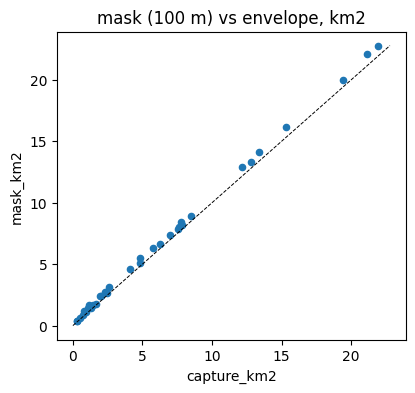

In [18]:
ax = summ.plot.scatter('capture_km2', 'mask_km2', figsize=(4.5, 4))
lim = summ[['capture_km2', 'mask_km2']].max().max()
ax.plot([0, lim], [0, lim], 'k--', lw=0.7)
ax.set_title('mask (100 m) vs envelope, km2');

## 6. Maps

`plot` draws any combination of the paths, the capture polygons and the mask
(`path`, `capture`, `cz_mask` -- the last two need their `build_*` first),
plus the seeding points.  Paths are coloured by `layer` (legend) or by
altitude `z` (colorbar), or drawn plain with `color_by=None`.  Every cosmetic
choice is a keyword: `base_fontsize` scales every text on the figure,
`font`, `figsize`, the colours, the map furniture, and the basemap
(`basemap_source` is one of esri / esri_gray / esri_street / esri_imagery /
topo / positron / voyager / osm or any XYZ URL; `tile` is the zoom).  It
returns `(fig, ax)` and draws on a given `ax`.

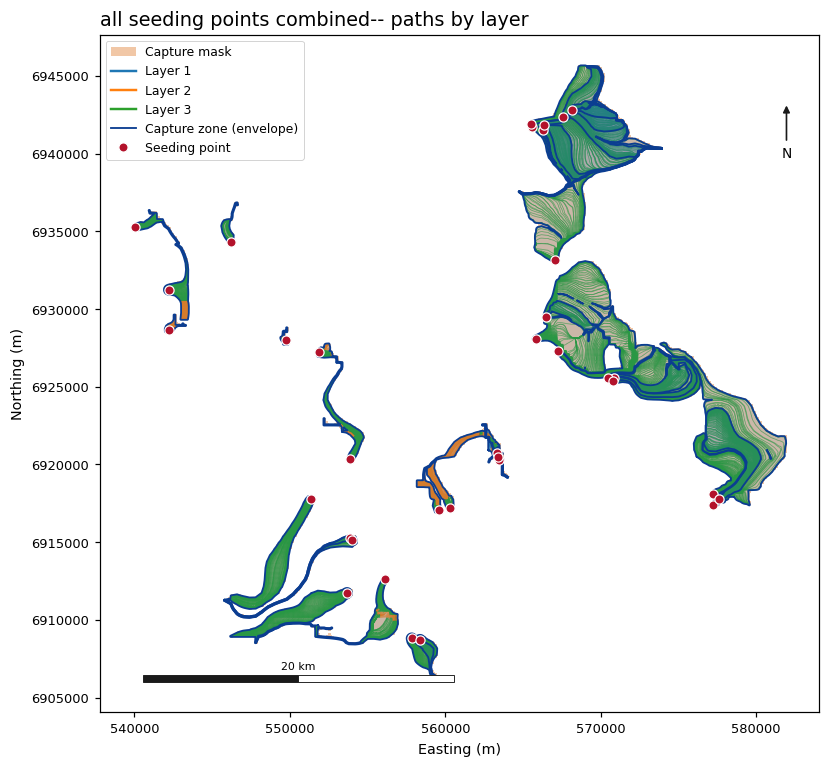

In [19]:
tr.plot(capture=True, cz_mask=True, color_by='layer', basemap=False,
        title='all seeding points combined-- paths by layer', figsize=(9, 8));

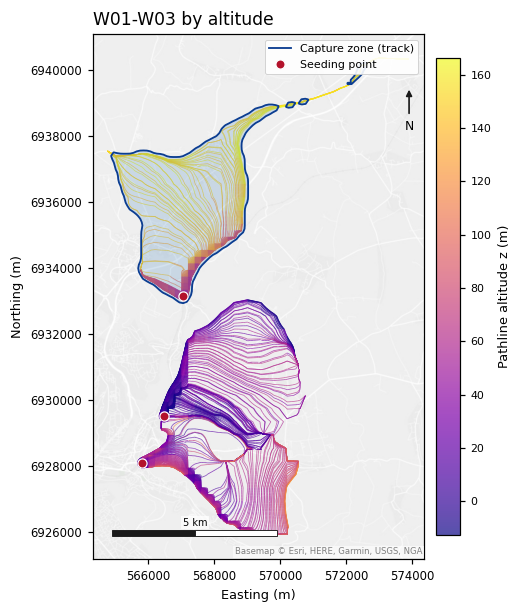

In [14]:
tr.plot(capture=True, color_by='z', cmap='plasma', id=["W01", 2, 114],
        basemap=True, basemap_source='esri_gray', title='W01-W03 by altitude',
        base_fontsize=8, save=os.path.join(OUT, 'W01_W03_z.png'));

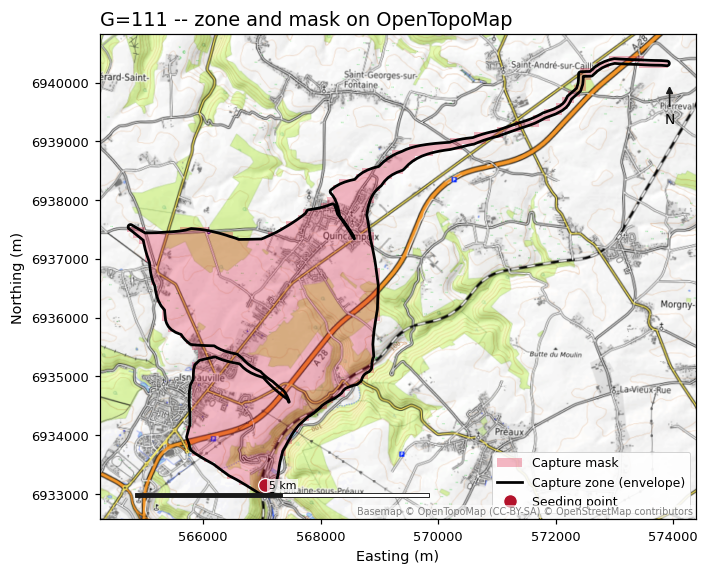

In [21]:
tr.plot(path=False, capture=True, cz_mask=True, id='111',
        basemap=True, basemap_source='topo', tile=13,
        zone_color='black', zone_fill='none', zone_width=1.8,
        mask_color='crimson', mask_alpha=0.3, seed_size=9,
        legend_loc='lower right', title='G=111 -- zone and mask on OpenTopoMap');

## 7. Without a project

The two readers stand on their own when there is no `.rma` at hand, and the
class can be built from their output.  Without seeding points the paths are
grouped by the `Group =` tag of `trajmar.out` (keys `G1`, `G2` ...), or all
together under `ALL` when the file carries none.

In [15]:
from martpy.utils.trajectory import Trajectory, read_deptr, read_trajmar

test = os.path.join(os.path.dirname(mart.__file__), '..', '..', 'tests', 'data', 'traj')
henry = Trajectory(read_deptr(os.path.join(test, 'Henry_Perma.deptr')),
                   read_trajmar(os.path.join(test, 'trajmar.out')))
print(henry)
henry.summary()

Trajectory: 40 paths, 3927 vertices, 1 seeding points (0 unattributed)
    ALL: 40 paths



,group,x,y,z,layer,radius,npart,ntraj,method,path_m,t_max
key,,,,,,,,,,,
ALL,-1,100.0,-0.5,NaN,1,NaN,-1,40,none,87.030493,80.0


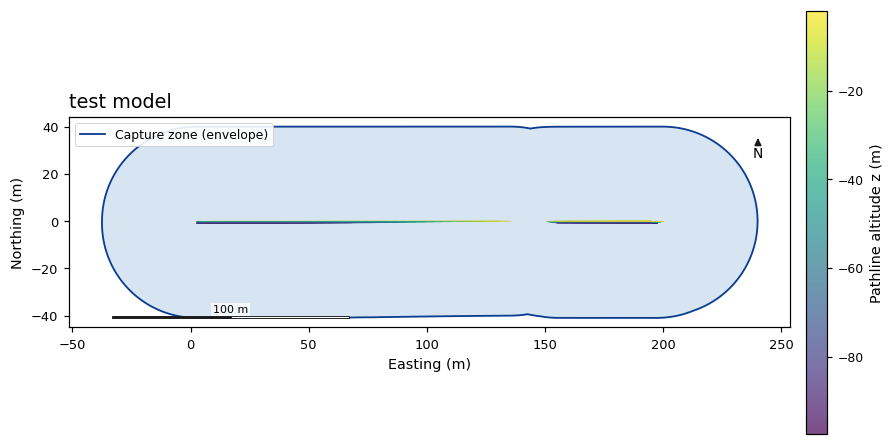

In [28]:
henry_cz = henry.build_capture(method='envelope', offset_m=20.0)

henry.plot(capture=True, cz_mask=False, color_by='z', basemap=False,
        title='test model', figsize=(9, 5));